# Vertical Federated Unlearning (VFU): Research Landscape & Exploratory Benchmark

This notebook is a **standalone** companion to `Part_1.ipynb`. It synthesizes recent VFU literature, proposes **Q1-journal–aligned research threads**, and runs a **minimal reproducible harness**: split neural VFL, sample-level unlearning, and **utility vs. verification** metrics (including a stronger auditor on intermediate representations).

---
## What “Q1” usually expects in this space

Venues such as **IEEE TIFS**, **IEEE TDSC**, **Information Fusion**, **Information Sciences**, and top ML venues care about: (i) a **clear threat model** (who sees what: logits, embeddings, gradients); (ii) **baselines** including retraining or certified methods when claims are strong; (iii) **standardized metrics** (utility drop, unlearning cost, attack success); and (iv) **honest limitations** when guarantees are empirical.

---
## Literature snapshot (2023–2025)

| Direction | Representative idea | Why it matters |
|-----------|---------------------|----------------|
| **Optimization / distillation** | VFU-KD / VFU-GA (Varshney et al., arXiv:2501.13683) | Practical unlearning for client / feature / sample targets |
| **Certified / anytime** | Theoretically certified asynchronous VFL unlearning (e.g., arXiv:2502.17081) | Bridges compliance language with formal statements |
| **Verification** | Backdoor- or certification-style checks (e.g., arXiv:2412.11476) | Unlearning is partly an **audit** problem |
| **Representation-centric** | Representation misdirection / encoder-focused forgetting (e.g., REMISVFU, arXiv:2512.10348) | Embeddings often leak more than logits |
| **Benchmarks** | Public VFU benchmarks (e.g., Vertical-Federated-Unlearning-Benchmark on GitHub) | Reduces cherry-picking and enables fair comparisons |

---
## Publishable gaps (concrete paper sketches)

1. **Multi-level verification for VFU**  
   Unify *logit-based*, *embedding-based*, and (where available) *gradient-based* membership audits under one protocol; show when KD/GA “passes” weak tests but fails stronger ones—your `Project_Report.tex` already points at this gap.

2. **Feature-unlearning with dependency structure**  
   When Party B drops a column correlated with Party A’s features, quantify **residual influence** via causal / redundancy graphs; propose unlearning + auditing that conditions on cross-party correlation.

3. **Cost–guarantee Pareto front**  
   Plot compute/communication vs. attack AUC for retrain-from-scratch, approximate methods, and (if implemented) certified variants; target **anytime** or **sequential** deletion streams.

4. **VFU under non-IID vertical splits**  
   Real institutions have different missingness and quality; study unlearning stability when passive parties have shifted feature distributions.

5. **Regulatory alignment**  
   Map methods to GDPR “erasure” narratives: *which artifacts* must be deleted (checkpoints, embedding caches, optimizer states)?

The code below **instantiates threads (1) and (3)** in miniature: compare approximate unlearning to a **retrain oracle** and run **two MIA strengths** (logits vs. embeddings).

## 1. Setup

In [1]:
# Optional: pip install pandas numpy scikit-learn torch matplotlib seaborn
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 2. Data: UCI Adult (tabular VFL)

In [2]:
def load_adult():
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    columns = [
        "age", "workclass", "fnlwgt", "education", "education_num",
        "marital_status", "occupation", "relationship", "race", "sex",
        "capital_gain", "capital_loss", "hours_per_week", "native_country", "income",
    ]
    df = pd.read_csv(url, names=columns, sep=",\\s*", engine="python", na_values="?")
    df = df.dropna()
    df["income"] = (df["income"] == ">50K").astype(int)
    cat = ["workclass", "education", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]
    for c in cat:
        df[c] = LabelEncoder().fit_transform(df[c])
    X = df.drop("income", axis=1)
    y = df["income"].astype(np.float32)
    return X, y


X_raw, y_raw = load_adult()
print(X_raw.shape, y_raw.value_counts().to_dict())

(30162, 14) {0.0: 22654, 1.0: 7508}


## 3. Vertical partition + VFL model (2 parties, active holds labels)

In [3]:
def partition_features_equal(X: pd.DataFrame, n_parties: int, seed: int = SEED):
    rng = np.random.default_rng(seed)
    feats = list(X.columns)
    rng.shuffle(feats)
    splits = []
    k = len(feats) // n_parties
    for i in range(n_parties):
        start = i * k
        end = None if i == n_parties - 1 else (i + 1) * k
        splits.append(feats[start:end])
    return splits


class BottomNet(nn.Module):
    def __init__(self, in_dim, hid=64, emb=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hid),
            nn.ReLU(),
            nn.BatchNorm1d(hid),
            nn.Dropout(0.25),
            nn.Linear(hid, emb),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)


class TopNet(nn.Module):
    def __init__(self, in_dim, hid=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hid),
            nn.ReLU(),
            nn.BatchNorm1d(hid),
            nn.Dropout(0.25),
            nn.Linear(hid, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x)


class SplitVFL(nn.Module):
    def __init__(self, party_dims, emb=32, hid=64, dev=None):
        super().__init__()
        dev = dev or device
        self.bottoms = nn.ModuleList([BottomNet(d, hid, emb).to(dev) for d in party_dims])
        self.top = TopNet(emb * len(party_dims), hid).to(dev)
        self.dev = dev

    def forward(self, xs, return_emb=False):
        embs = [b(x) for b, x in zip(self.bottoms, xs)]
        h = torch.cat(embs, dim=1)
        out = self.top(h)
        return (out, h) if return_emb else out

    def all_params(self):
        return list(self.parameters())


def tensors_from_partition(X_df, y_series, feat_splits, test_size=0.25):
    X_parts = [X_df[cols].values.astype(np.float32) for cols in feat_splits]
    y = y_series.values.astype(np.float32)
    n = len(y)
    idx = np.arange(n)
    tr, te = train_test_split(idx, test_size=test_size, random_state=SEED, stratify=y)
    scalers = []
    Xtr, Xte = [], []
    for Xp in X_parts:
        sc = StandardScaler()
        Xtr.append(torch.tensor(sc.fit_transform(Xp[tr]), dtype=torch.float32, device=device))
        Xte.append(torch.tensor(sc.transform(Xp[te]), dtype=torch.float32, device=device))
        scalers.append(sc)
    ytr = torch.tensor(y[tr], dtype=torch.float32, device=device).unsqueeze(1)
    yte = torch.tensor(y[te], dtype=torch.float32, device=device).unsqueeze(1)
    return Xtr, Xte, ytr, yte, tr, te, scalers


N_PARTIES = 2
splits = partition_features_equal(X_raw, N_PARTIES)
for i, s in enumerate(splits):
    print(f"Party {i} ({len(s)} feats):", s[:6], "..." if len(s) > 6 else "")

party_dims = [len(s) for s in splits]
Xtr, Xte, ytr, yte, train_idx, test_idx, scalers = tensors_from_partition(X_raw, y_raw, splits)
model = SplitVFL(party_dims).to(device)

Party 0 (7 feats): ['occupation', 'relationship', 'sex', 'education', 'age', 'capital_loss'] ...
Party 1 (7 feats): ['capital_gain', 'marital_status', 'fnlwgt', 'education_num', 'hours_per_week', 'workclass'] ...


## 4. Training helpers

In [4]:
bce = nn.BCELoss()


def train_epochs(m: SplitVFL, Xtr, ytr, epochs=40, lr=1e-3, bs=512, verbose=True):
    opt = optim.Adam(m.all_params(), lr=lr)
    m.train()
    n = ytr.shape[0]
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(n, device=device)
        loss_acc = 0.0
        steps = 0
        for start in range(0, n, bs):
            idx = perm[start : start + bs]
            xb = [X[idx] for X in Xtr]
            yb = ytr[idx]
            opt.zero_grad()
            pred = m(xb)
            loss = bce(pred, yb)
            loss.backward()
            opt.step()
            loss_acc += loss.item()
            steps += 1
        hist.append(loss_acc / max(steps, 1))
        if verbose and (ep + 1) % 10 == 0:
            print(f"epoch {ep+1} loss {hist[-1]:.4f}")
    return hist


@torch.no_grad()
def metrics_split(m: SplitVFL, Xte, yte):
    m.eval()
    p = m(Xte).cpu().numpy().ravel()
    yt = yte.cpu().numpy().ravel()
    yhat = (p >= 0.5).astype(int)
    acc = accuracy_score(yt, yhat)
    try:
        auc = roc_auc_score(yt, p)
    except ValueError:
        auc = float("nan")
    return acc, auc, p


t0 = time.perf_counter()
train_epochs(model, Xtr, ytr, epochs=45, lr=1e-3)
t_train = time.perf_counter() - t0
acc0, auc0, _ = metrics_split(model, Xte, yte)
print(f"Post-train: acc={acc0:.4f} auc={auc0:.4f} time={t_train:.1f}s")

epoch 10 loss 0.3485
epoch 20 loss 0.3307
epoch 30 loss 0.3154
epoch 40 loss 0.3116
Post-train: acc=0.8512 auc=0.9057 time=12.5s


## 5. Choose forget set (sample-level VFU)

We remove a random subset of **training** indices and compare:
- **Oracle**: retrain a fresh model from scratch on retained data only.
- **VFU-GA-style**: short gradient **ascent** on BCE loss on forget samples (approximate unlearning).
- **Retain fine-tune**: continue training only on retained set (simple baseline).

For a paper, vary forget fraction, class balance, and repeated sequential deletions.

In [5]:
FORGET_FRAC = 0.05
rng = np.random.default_rng(SEED)
n_tr = ytr.shape[0]
forget_mask = np.zeros(n_tr, dtype=bool)
n_forget = max(1, int(FORGET_FRAC * n_tr))
forget_pos = rng.choice(n_tr, size=n_forget, replace=False)
forget_mask[forget_pos] = True
retain_mask = ~forget_mask
print("Forget / retain:", forget_mask.sum(), retain_mask.sum())

Xtr_forget = [X[forget_mask] for X in Xtr]
y_forget = ytr[forget_mask]
Xtr_retain = [X[retain_mask] for X in Xtr]
y_retain = ytr[retain_mask]

# Map forget positions to global train indices (for auditing)
forget_global_idx = train_idx[forget_pos]

Forget / retain: 1131 21490


## 6. Unlearning procedures + wall-clock cost (Pareto-style metric)

In [6]:
def clone_train_fresh(party_dims, X_list, y_labels, epochs=45, lr=1e-3):
    m = SplitVFL(party_dims).to(device)
    t0 = time.perf_counter()
    train_epochs(m, X_list, y_labels, epochs=epochs, lr=lr, verbose=False)
    return m, time.perf_counter() - t0


def gradient_ascent_forget(m, X_f, y_f, steps=80, lr=5e-4):
    opt = optim.Adam(m.all_params(), lr=lr)
    m.train()
    t0 = time.perf_counter()
    for _ in range(steps):
        opt.zero_grad()
        pred = m([x for x in X_f])
        loss = bce(pred, y_f)
        (-loss).backward()
        opt.step()
    return m, time.perf_counter() - t0


def finetune_retain(m, X_r, y_r, epochs=15, lr=1e-4):
    opt = optim.Adam(m.all_params(), lr=lr)
    m.train()
    t0 = time.perf_counter()
    n = y_r.shape[0]
    for ep in range(epochs):
        perm = torch.randperm(n, device=device)
        for start in range(0, n, 512):
            idx = perm[start : start + 512]
            xb = [X[idx] for X in X_r]
            yb = y_r[idx]
            opt.zero_grad()
            loss = bce(m(xb), yb)
            loss.backward()
            opt.step()
    return m, time.perf_counter() - t0


# Start from trained model states
import copy

state_ref = copy.deepcopy(model.state_dict())

# Oracle retrain
model_oracle, t_oracle = clone_train_fresh(party_dims, Xtr_retain, y_retain, epochs=45)

# GA on copy of trained model
model_ga = SplitVFL(party_dims).to(device)
model_ga.load_state_dict(copy.deepcopy(state_ref))
model_ga, t_ga = gradient_ascent_forget(model_ga, Xtr_forget, y_forget, steps=100, lr=5e-4)
model_ga, t_ft = finetune_retain(model_ga, Xtr_retain, y_retain, epochs=12, lr=1e-4)
t_ga_total = t_ga + t_ft

# Retain-only fine-tune from original (no explicit forget push)
model_ft = SplitVFL(party_dims).to(device)
model_ft.load_state_dict(copy.deepcopy(state_ref))
model_ft, t_retain_ft = finetune_retain(model_ft, Xtr_retain, y_retain, epochs=20, lr=1e-4)

rows = []
for name, m_, tc in [
    ("pre_unlearn", model, 0.0),
    ("oracle_retrain", model_oracle, t_oracle),
    ("vfu_ga+retain_ft", model_ga, t_ga_total),
    ("retain_finetune_only", model_ft, t_retain_ft),
]:
    acc, auc, _ = metrics_split(m_, Xte, yte)
    rows.append({"method": name, "acc": acc, "auc": auc, "seconds": tc})

pd.DataFrame(rows)

,method,acc,auc,seconds
0,pre_unlearn,0.851213,0.905715,0.000000
1,oracle_retrain,0.848163,0.904712,10.121506
2,vfu_ga+retain_ft,0.833046,0.880907,3.198705
3,retain_finetune_only,0.853468,0.906112,4.095491


## 7. Verification: membership inference (weak vs. strong auditor)

**Attack features**
- *Weak*: loss computed from **final probability** vs label (classic Shokri-style scalar signal).
- *Stronger (VFL-specific)*: concatenate **party embeddings** (what passive parties could leak or infer in some protocols) and train a logistic **shadow attack** on member vs non-member.

We label **members** = forget set was in training; **non-members** = held-out test samples. After unlearning, the model should reduce separability for the forget set *if* unlearning truly removes their influence. (This is an **empirical audit**, not a cryptographic guarantee.)

> Paper angle: show embedding-level AUC stays high while logit-loss AUC drops—motivating **representation scrubbing** (related to REMISVFU-style ideas).

              method  mia_logit_loss_auc  mia_embedding_auc
         pre_unlearn            0.487267           0.491477
      oracle_retrain            0.479194           0.511845
    vfu_ga+retain_ft            0.469728           0.499362
retain_finetune_only            0.486218           0.498052


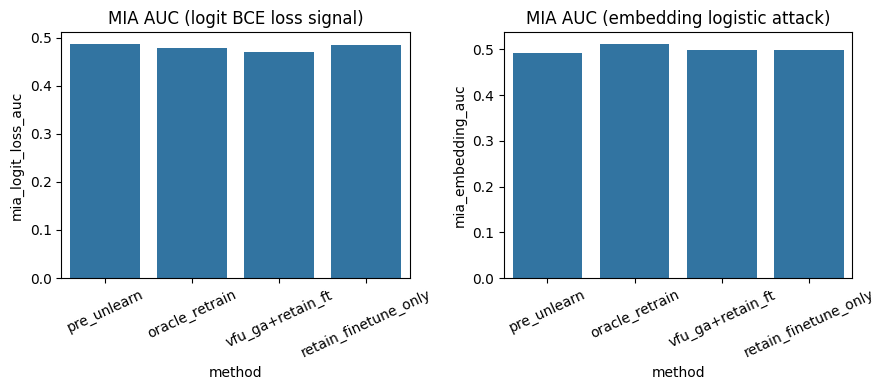

In [7]:
@torch.no_grad()
def collect_signals(m: SplitVFL, X_list, y_labels):
    m.eval()
    pred, emb = m(X_list, return_emb=True)
    p = pred.clamp(1e-6, 1 - 1e-6)
    y = y_labels
    bce_elem = -(y * p.log() + (1 - y) * (1 - p).log())
    return bce_elem.cpu().numpy().ravel(), emb.cpu().numpy()


def mia_auc_logit_loss(model_under_test, X_mem, y_mem, X_non, y_non):
    # Features: per-sample BCE loss (lower for members typically)
    l_mem, _ = collect_signals(model_under_test, X_mem, y_mem)
    l_non, _ = collect_signals(model_under_test, X_non, y_non)
    X_attack = np.concatenate([l_mem.reshape(-1, 1), l_non.reshape(-1, 1)], axis=0)
    y_attack = np.array([1] * len(l_mem) + [0] * len(l_non))
    try:
        return roc_auc_score(y_attack, -X_attack.ravel())  # higher loss => less "member-like"
    except ValueError:
        return float("nan")


def mia_auc_embedding(model_under_test, X_mem, y_mem, X_non, y_non, seed=0):
    _, E_mem = collect_signals(model_under_test, X_mem, y_mem)
    _, E_non = collect_signals(model_under_test, X_non, y_non)
    X = np.vstack([E_mem, E_non])
    y = np.array([1] * len(E_mem) + [0] * len(E_non))
    tr_i, te_i = train_test_split(np.arange(len(y)), test_size=0.35, random_state=seed, stratify=y)
    clf = LogisticRegression(max_iter=200, class_weight="balanced")
    clf.fit(X[tr_i], y[tr_i])
    s = clf.predict_proba(X[te_i])[:, 1]
    return roc_auc_score(y[te_i], s)


# Non-members: test set (subset for balance)
n_m = y_forget.shape[0]
sub_te = torch.randperm(yte.shape[0], device=device)[: n_m * 2]
X_non = [X[sub_te] for X in Xte]
y_non = yte[sub_te]
X_mem = Xtr_forget
y_mem = y_forget

audit_rows = []
for name, m_ in [
    ("pre_unlearn", model),
    ("oracle_retrain", model_oracle),
    ("vfu_ga+retain_ft", model_ga),
    ("retain_finetune_only", model_ft),
]:
    audit_rows.append(
        {
            "method": name,
            "mia_logit_loss_auc": mia_auc_logit_loss(m_, X_mem, y_mem, X_non, y_non),
            "mia_embedding_auc": mia_auc_embedding(m_, X_mem, y_mem, X_non, y_non),
        }
    )

df_audit = pd.DataFrame(audit_rows)
print(df_audit.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
sns.barplot(data=df_audit, x="method", y="mia_logit_loss_auc", ax=ax[0])
ax[0].set_title("MIA AUC (logit BCE loss signal)")
ax[0].tick_params(axis="x", rotation=25)
sns.barplot(data=df_audit, x="method", y="mia_embedding_auc", ax=ax[1])
ax[1].set_title("MIA AUC (embedding logistic attack)")
ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 8. How to turn this into a Q1 submission (checklist)

1. **Problem statement**: Specify unlearning target (sample / feature / client), adversary knowledge (black-box logits vs. white-box embeddings vs. gradients), and compliance interpretation.
2. **Baselines**: Oracle retrain, your VFU-GA/KD implementations from `Part_1.ipynb`, and recent arXiv methods you reproduce via the [Vertical-Federated-Unlearning-Benchmark](https://github.com/bryanhx/Vertical-Federated-Unlearning-Benchmark) where possible.
3. **Metrics table**: Utility (acc/AUC/F1), **forget-set** behavior (e.g., confidence on forgotten labels), **attack AUC** under multiple auditors, **time/communication**.
4. **Ablations**: Forget ratio, party count, embedding dimension, sequential requests, label imbalance.
5. **Theory or certificates**: If targeting TIFS/TDSC, pair empirical results with formal statements (even partial) or tight limitations.

---
### Suggested high-impact title patterns
- *“Hierarchical Verification for Vertical Federated Unlearning: When Logits Lie”*
- *“Anytime Feature Withdrawal in VFL: Cost–Privacy Tradeoffs under GDPR”*
- *“Certified vs. Approximate VFU: A Unified Empirical Framework”*

---
**References (open access / preprints)**  
- Varshney et al., *Unlearning Clients, Features and Samples in Vertical Federated Learning*, [arXiv:2501.13683](https://arxiv.org/abs/2501.13683)  
- *Forgetting Any Data at Any Time* (certified VFL unlearning), [arXiv:2502.17081](https://arxiv.org/abs/2502.17081)  
- *Vertical Federated Unlearning via Backdoor Certification*, [arXiv:2412.11476](https://arxiv.org/abs/2412.11476)  
- REMISVFU, [arXiv:2512.10348](https://arxiv.org/abs/2512.10348)